# Radar Hedef Tespit Sistemi
## Genetik Algoritma ve Diferansiyel Evrim ile Optimal Eşik Belirleme

---

| Bilgi | Detay |
|---|---|
| **Konu** | Evrimsel Optimizasyon - Radar Sinyal İşleme |
| **Yöntemler** | Genetik Algoritma (GA), Diferansiyel Evrim (DE) |
| **Dil** | Python 3 |
| **Kütüphaneler** | NumPy, SciPy, Matplotlib, PyGAD |

---

### Proje Özeti

Radar sistemleri hedef tespit ederken iki temel hatayla karşılaşır:

- **Yanlış Alarm (False Positive):** Hedef yokken "var" demek
- **Kaçırma (False Negative):** Hedef varken "yok" demek

Bu iki hata birbirine bağlıdır: birini azaltmak diğerini artırır. Bu çalışmanın amacı, **Genetik Algoritma** ve **Diferansiyel Evrim** kullanarak bu iki hatanın dengesini en iyi kuran eşik değerini bulmaktır.

### Kullanılan Sinyal Modeli

$$\text{Hedef YOK: } X \sim N(0, \sigma^2)$$
$$\text{Hedef VAR: } X \sim N(\mu, \sigma^2)$$
$$\text{SNR} = \frac{\mu}{\sigma}$$

---
## Bölüm 1 — Kütüphaneler

Projede kullanılan Python kütüphaneleri ve amaçları:

| Kütüphane | Amaç |
|---|---|
| `numpy` | Sayısal hesaplama, veri üretimi |
| `scipy.stats` | Normal dağılım (PDF, CDF) |
| `scipy.optimize` | Diferansiyel Evrim |
| `matplotlib` | Grafik ve görselleştirme |
| `pygad` | Genetik Algoritma |

In [1]:
# ============================================================
# KÜTÜPHANE YÜKLEMELERİ
# ============================================================

import numpy as np                                    # Sayısal işlemler
import matplotlib.pyplot as plt                       # Grafik çizimi
import matplotlib.gridspec as gridspec                # Çoklu panel grafik düzeni
from scipy import stats                               # İstatistiksel dağılımlar
from scipy.optimize import differential_evolution    # DE algoritması
import warnings
warnings.filterwarnings('ignore')                     # Uyarı mesajlarını gizle

# PyGAD: Python Genetik Algoritma kütüphanesi
# Yüklü değilse otomatik olarak yükle
try:
    import pygad
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'pygad', '-q'])
    import pygad

# Rastgele sayı üretiminde tekrarlanabilirlik için seed belirleme
# Aynı seed = her çalıştırmada aynı sonuç (akademik çalışmalarda zorunlu)
np.random.seed(42)

print('Tüm kütüphaneler başarıyla yüklendi.')
print(f'PyGAD versiyon: {pygad.__version__}')

Tüm kütüphaneler başarıyla yüklendi.
PyGAD versiyon: 3.9.2


---
## Bölüm 2 — Parametreler ve Sinyal Modeli

### Neden Gaussian Dağılım?

Radar gürültüsü çok sayıda küçük ve bağımsız kaynaktan gelir:
atmosferik etkileşim, elektronik devre ısısı, termal gürültü vb.
**Merkezi Limit Teoremi** gereği bu kaynakların toplamı **Normal (Gaussian) dağılıma** yaklaşır.

### SNR — Sinyal Gürültü Oranı

SNR, sinyalin gürültüden ne kadar ayırt edilebildiğini ölçer:

| SNR Değeri | Yorum |
|---|---|
| SNR < 1 | Sinyal gürültü içinde kaybolur, tespit neredeyse imkânsız |
| SNR = 2 | Orta zorluk — bu çalışmanın senaryosu |
| SNR > 3 | İki dağılım net ayrılır, tespit kolaydır |

In [2]:
# ============================================================
# SİSTEM PARAMETRELERİ
# ============================================================

mu    = 3.0    # Sinyal gücü: hedef varken sinyalin ortalaması
               # Gerçek sistemde hedefin radar kesit alanı ve mesafeye göre belirlenir

sigma = 1.5    # Gürültü büyüklüğü: sistemin gürültü standart sapması
               # Düşük sigma = temiz ortam, yüksek sigma = gürültülü ortam

n     = 1000   # Toplam ölçüm sayısı (500 hedef var, 500 hedef yok)
n_her = n // 2 # Her sınıf için eşit örnek sayısı (dengeli veri seti)

# SNR hesabı: sinyalin gürültüye oranı
# Yüksek SNR → iki dağılım birbirinden uzaklaşır → kolay ayırt etme
snr = mu / sigma

# Parametreleri özet olarak yazdır
print('='*40)
print('SİSTEM PARAMETRELERİ')
print('='*40)
print(f'Sinyal gücü    (mu)    : {mu}')
print(f'Gürültü        (sigma) : {sigma}')
print(f'SNR            (mu/σ)  : {snr:.2f}')
print(f'Toplam ölçüm           : {n}')
print(f'Hedef var / yok        : {n_her} / {n_her}')
print('='*40)

SİSTEM PARAMETRELERİ
Sinyal gücü    (mu)    : 3.0
Gürültü        (sigma) : 1.5
SNR            (mu/σ)  : 2.00
Toplam ölçüm           : 1000
Hedef var / yok        : 500 / 500


---
## Bölüm 3 — Sentetik Veri Üretimi

### Neden Sentetik Veri?

Gerçek radar verisi **gizlilik sınıflandırması** nedeniyle kamuya açık değildir.
Ancak istatistiksel modeli bildiğimizde, o modelden gerçekçi veri üretmek mümkündür.
Bu yaklaşım akademik literatürde **Monte Carlo Simülasyonu** olarak bilinir ve
savunma araştırmalarında yaygın şekilde kullanılır.

### Veri Üretim Mantığı

```
Hedef YOK (500 ölçüm) : X ~ N(0,   1.5)  → sadece gürültü
Hedef VAR (500 ölçüm) : X ~ N(3.0, 1.5)  → sinyal + gürültü
```

In [3]:
# ============================================================
# SENTETİK VERİ ÜRETİMİ
# ============================================================

# Senaryo 1: Hedef YOK
# Sadece gürültü var, sinyal yok
# Ortalama = 0 çünkü sinyal katkı yapmaz
gurultu_sinyali = np.random.normal(loc=0, scale=sigma, size=n_her)

# Senaryo 2: Hedef VAR
# Gerçek sinyal (mu) + üzerine eklenen gürültü (sigma)
# Ortalama = mu çünkü hedefin kendi yansıması var
hedef_sinyali = np.random.normal(loc=mu, scale=sigma, size=n_her)

# İki sinyali birleştir: önce gürültü, sonra sinyal
# Bu sıralama etiketlerle eşleşmeli!
olcumler  = np.concatenate([gurultu_sinyali, hedef_sinyali])

# Gerçek etiketler: 0 = hedef yok, 1 = hedef var
# Makine öğreniminde 'ground truth' olarak adlandırılır
etiketler = np.concatenate([np.zeros(n_her), np.ones(n_her)])

# Veri kalite kontrolü
print('VERİ ÖZETİ')
print('-'*40)
print(f'Toplam ölçüm sayısı  : {len(olcumler)}')
print(f'Hedef yok (sınıf 0)  : {int(np.sum(etiketler==0))}')
print(f'Hedef var (sınıf 1)  : {int(np.sum(etiketler==1))}')
print(f'Gürültü ortalaması   : {gurultu_sinyali.mean():.3f}  (beklenen: 0.000)')
print(f'Sinyal ortalaması    : {hedef_sinyali.mean():.3f}  (beklenen: {mu:.3f})')
print(f'Gürültü std          : {gurultu_sinyali.std():.3f}  (beklenen: {sigma:.3f})')
print(f'Sinyal std           : {hedef_sinyali.std():.3f}  (beklenen: {sigma:.3f})')

VERİ ÖZETİ
----------------------------------------
Toplam ölçüm sayısı  : 1000
Hedef yok (sınıf 0)  : 500
Hedef var (sınıf 1)  : 500
Gürültü ortalaması   : 0.010  (beklenen: 0.000)
Sinyal ortalaması    : 3.048  (beklenen: 3.000)
Gürültü std          : 1.470  (beklenen: 1.500)
Sinyal std           : 1.466  (beklenen: 1.500)


---
## Bölüm 4 — Sinyal Dağılımlarının Görselleştirilmesi

Bu grafik projenin en temel görseli. İki dağılımın ne kadar iç içe geçtiği,
yani problemin ne kadar zor olduğunu doğrudan gösterir.

**Grafiği okuma rehberi:**
- 🔵 Mavi bölge: gürültünün yayılımı (hedef yok senaryosu)
- 🟠 Turuncu bölge: sinyalin yayılımı (hedef var senaryosu)
- Örtüşme alanı: hatanın kaçınılmaz olduğu bölge
- 🟢 Yeşil kesik çizgi: GA'nın bulduğu optimal eşik değeri

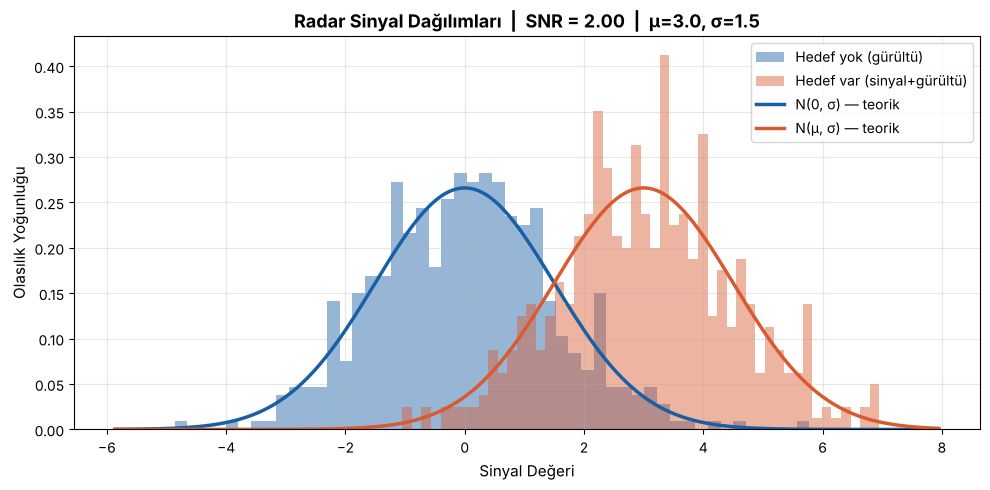

Grafik kaydedildi → dagilim_grafigi.png


In [4]:
# ============================================================
# SİNYAL DAĞILIM GRAFİĞİ
# ============================================================
# Bu grafik ilerleyen bölümde güncellenerek eşik değeri eklenir
# Şu an sadece ham dağılımlar gösterilmektedir

x_eksen = np.linspace(olcumler.min()-1, olcumler.max()+1, 300)

fig, ax = plt.subplots(figsize=(10, 5))

# Histogram: gözlemlenen veri dağılımı
ax.hist(gurultu_sinyali, bins=50, density=True, alpha=0.45,
        color='#185FA5', label='Hedef yok (gürültü)')
ax.hist(hedef_sinyali, bins=50, density=True, alpha=0.45,
        color='#D85A30', label='Hedef var (sinyal+gürültü)')

# Teorik eğri: N(0, sigma) ve N(mu, sigma)
# stats.norm.pdf() → Normal dağılım olasılık yoğunluk fonksiyonu
ax.plot(x_eksen, stats.norm.pdf(x_eksen, 0,  sigma),
        color='#185FA5', lw=2.5, label='N(0, σ) — teorik')
ax.plot(x_eksen, stats.norm.pdf(x_eksen, mu, sigma),
        color='#D85A30', lw=2.5, label='N(μ, σ) — teorik')

ax.set_title(f'Radar Sinyal Dağılımları  |  SNR = {snr:.2f}  |  μ={mu}, σ={sigma}',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Sinyal Değeri', fontsize=11)
ax.set_ylabel('Olasılık Yoğunluğu', fontsize=11)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('dagilim_grafigi.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafik kaydedildi → dagilim_grafigi.png')

### 📊 Dağılım Grafiği Yorumu

> **SNR = 2.0 olduğunda iki dağılım birbirine oldukça yakındır.**
>
> Mavi ve turuncu bölgeler arasında belirgin bir örtüşme vardır.
> Bu örtüşme bölgesindeki hiçbir eşik değeri mükemmel bir ayrım yapamaz:
> eşik ne kadar sağa giderse yanlış alarm azalır ama gerçek hedefler de
> kaçırılmaya başlanır. Tam tersi de geçerlidir.
>
> **Bu, optimizasyonun neden gerekli olduğunu göstermektedir.**
> Gözle "iyi bir eşik" seçmek yerine, GA ve DE bu dengeyi matematiksel
> olarak en iyi kuran noktayı bulacaktır.

---
## Bölüm 5 — Fitness Fonksiyonu

### Fitness Fonksiyonu Nedir?

GA ve DE'ye **"neyin iyi, neyin kötü olduğunu"** öğreten fonksiyon.
Her aday eşik değeri bu fonksiyondan geçirilir ve bir puan alır.
Algoritma en yüksek puanlı noktayı bulmaya çalışır.

### Seçilen Fitness: TPR − FPR

$$\text{Skor} = TPR - FPR$$

| Metrik | Tanım | Hedef |
|---|---|---|
| **TPR** | Gerçek hedeflerin kaç tanesini yakaladık | Maksimize et |
| **FPR** | Kaç tane yanlış alarm verdik | Minimize et |
| **Skor** | TPR − FPR | Maksimize et |

Skor aralığı: **[−1, +1]**
- Skor = +1 → Mükemmel (TPR=1, FPR=0)
- Skor = 0  → Rastgele tahmin kadar iyi
- Skor = −1 → En kötü durum

In [5]:
# ============================================================
# FITNESS VE YARDIMCI FONKSİYONLAR
# ============================================================

def esik_uygula(esik):
    """
    Verilen eşik değerine göre tahmin üretir ve TPR/FPR hesaplar.

    Karar kuralı:
        ölçüm > eşik  →  'Hedef var' de  (tahmin = 1)
        ölçüm ≤ eşik  →  'Hedef yok' de (tahmin = 0)

    Parametreler:
        esik (float): Karar sınırı

    Dönüş:
        tpr (float): True Positive Rate  = TP / (TP + FN)
        fpr (float): False Positive Rate = FP / (FP + TN)
    """
    # Tahmin: eşikten büyük olan ölçümler 'hedef var' sayılır
    tahmin = (olcumler > esik).astype(int)

    # TPR: Gerçekten hedef olanlar arasında kaç tanesi doğru tahmin edildi
    # Hipotez testindeki 'güç (power)' kavramının radar karşılığı
    tpr = np.sum((tahmin == 1) & (etiketler == 1)) / np.sum(etiketler == 1)

    # FPR: Gerçekte hedef olmayanların kaç tanesi yanlışlıkla 'hedef var' dedi
    # Hipotez testindeki 'Tip I Hata' ile aynı mantık
    fpr = np.sum((tahmin == 1) & (etiketler == 0)) / np.sum(etiketler == 0)

    return tpr, fpr


def fitness_maksimize(esik):
    """
    GA için fitness fonksiyonu.
    GA maksimizasyon yaptığından direkt TPR − FPR döndürür.
    """
    tpr, fpr = esik_uygula(esik)
    return tpr - fpr


def fitness_minimize(esik_array):
    """
    DE için fitness fonksiyonu.
    DE minimizasyon yaptığından negatife çeviriyoruz:
        max(TPR − FPR)  ≡  min(−(TPR − FPR))
    DE dizi girişi bekler, bu yüzden esik_array[0] kullanılır.
    """
    tpr, fpr = esik_uygula(esik_array[0])
    return -(tpr - fpr)   # Negatif: minimizasyonu maksimizasyona çevir


# --- Fonksiyon testi ---
# Teorik olarak optimal eşik iki dağılımın kesiştiği noktaya yakın olmalı
# Gaussian dağılımlar için bu nokta yaklaşık olarak μ/2'dir
teorik_esik = mu / 2
test_tpr, test_fpr = esik_uygula(teorik_esik)

print('FITNESS FONKSİYON TESTİ')
print('-'*40)
print(f'Test eşiği (μ/2)  : {teorik_esik:.2f}')
print(f'TPR               : {test_tpr:.4f}  → Hedeflerin %{test_tpr*100:.1f}i yakalandı')
print(f'FPR               : {test_fpr:.4f}  → %{test_fpr*100:.1f} yanlış alarm')
print(f'Fitness skoru     : {test_tpr - test_fpr:.4f}')
print(f'\nNot: GA bu skordan daha iyisini bulmaya çalışacak.')

FITNESS FONKSİYON TESTİ
----------------------------------------
Test eşiği (μ/2)  : 1.50
TPR               : 0.8580  → Hedeflerin %85.8i yakalandı
FPR               : 0.1420  → %14.2 yanlış alarm
Fitness skoru     : 0.7160

Not: GA bu skordan daha iyisini bulmaya çalışacak.


---
## Bölüm 6 — Genetik Algoritma (GA)

### GA Nasıl Çalışır?

```
1. Başlangıç  : 100 rastgele eşik değeri oluştur (popülasyon)
2. Değerlendirme : Her eşik için TPR−FPR hesapla
3. Seçim      : En iyi 20 bireyi seç (ebeveyn)
4. Çaprazlama : Ebeveynleri birleştirerek yeni eşikler üret
5. Mutasyon   : Yeni eşiklerin %20'sinde küçük rastgele değişiklik yap
6. Tekrar     : 200 nesil boyunca 2−5 adımlarını tekrarla
7. Sonuç      : En yüksek skoru veren eşik değeri = cevap
```

### PyGAD Parametreleri

| Parametre | Değer | Anlamı |
|---|---|---|
| `num_generations` | 200 | Kaç nesil evrimleşsin |
| `sol_per_pop` | 100 | Her nesilde kaç birey |
| `num_parents_mating` | 20 | Kaç birey üreme hakkı kazansın |
| `mutation_percent_genes` | 20 | Genlerin yüzde kaçı mutasyona uğrasın |

In [6]:
# ============================================================
# GENETİK ALGORİTMA
# ============================================================

# Arama uzayının sınırları: eşik bu aralıkta aranacak
alt_sinir = float(olcumler.min())
ust_sinir = float(olcumler.max())

# PyGAD fitness sarmalayıcısı
# ga_instance ve solution_idx: PyGAD'ın zorunlu kıldığı parametreler
def ga_fitness_func(ga_instance, solution, solution_idx):
    """
    PyGAD'ın çağırdığı fitness fonksiyonu.
    solution[0]: tek boyutlu problemde eşik değeri
    Dönen değer ne kadar yüksekse o birey o kadar 'iyi'.
    """
    return fitness_maksimize(solution[0])

# Nesil takip listesi: her nesildeki en iyi fitness kaydedilir
# Bu liste ilerleyen grafik için kullanılır
ga_nesil_fitness = []

def on_nesil(ga_instance):
    """Her nesil sonunda otomatik çağrılır (callback)."""
    en_iyi_skor = ga_instance.best_solution()[1]
    ga_nesil_fitness.append(en_iyi_skor)

# GA modelini tanımla
ga_model = pygad.GA(
    num_generations        = 200,           # Maksimum nesil sayısı
    num_parents_mating     = 20,            # Her nesilde çaprazlama yapan birey sayısı
    sol_per_pop            = 100,           # Popülasyon büyüklüğü
    num_genes              = 1,             # Tek parametre: eşik değeri
    gene_space             = {'low': alt_sinir, 'high': ust_sinir},  # Arama uzayı
    fitness_func           = ga_fitness_func,
    mutation_percent_genes = 20,            # Mutasyon oranı
    on_generation          = on_nesil,      # Her nesil sonrası çağır
    random_seed            = 42,            # Tekrarlanabilirlik için
    suppress_warnings      = True
)

print('GA başlatılıyor...')
ga_model.run()   # GA'yı çalıştır

# En iyi çözümü al
ga_cozum, ga_fitness_deger, _ = ga_model.best_solution()
ga_esik = float(ga_cozum[0])               # Optimal eşik değeri
ga_tpr, ga_fpr = esik_uygula(ga_esik)      # Bu eşikle TPR ve FPR hesapla

print(f'\nGA SONUÇLARI')
print('='*40)
print(f'Optimal eşik değeri : {ga_esik:.4f}')
print(f'TPR (Doğru tespit)  : {ga_tpr:.4f}  ({ga_tpr:.1%})')
print(f'FPR (Yanlış alarm)  : {ga_fpr:.4f}  ({ga_fpr:.1%})')
print(f'Fitness skoru       : {ga_fitness_deger:.4f}')
print(f'Nesil sayısı        : {len(ga_nesil_fitness)}')
print('='*40)

GA başlatılıyor...



GA SONUÇLARI
Optimal eşik değeri : 1.4642
TPR (Doğru tespit)  : 0.8680  (86.8%)
FPR (Yanlış alarm)  : 0.1420  (14.2%)
Fitness skoru       : 0.7260
Nesil sayısı        : 200


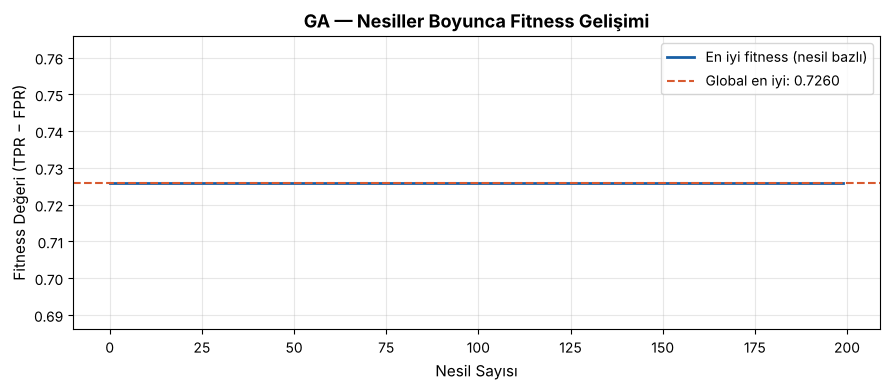

In [7]:
# ============================================================
# GA NESİL GRAFİĞİ
# ============================================================
# Bu grafik GA'nın nasıl öğrendiğini gösterir:
# x ekseni: nesil (zaman)
# y ekseni: o nesildeki en iyi fitness değeri
# Eğri ne kadar hızlı yükselirse GA o kadar hızlı öğreniyor demektir

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(ga_nesil_fitness, color='#185FA5', linewidth=2,
        label='En iyi fitness (nesil bazlı)')

# Son elde edilen en iyi değeri işaretleyen yatay çizgi
ax.axhline(ga_fitness_deger, color='#D85A30', linestyle='--',
           linewidth=1.5, label=f'Global en iyi: {ga_fitness_deger:.4f}')

ax.set_title('GA — Nesiller Boyunca Fitness Gelişimi',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Nesil Sayısı', fontsize=11)
ax.set_ylabel('Fitness Değeri (TPR − FPR)', fontsize=11)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('ga_nesil_grafigi.png', dpi=150, bbox_inches='tight')
plt.show()

### 📈 GA Nesil Grafiği Yorumu

> **Grafik GA'nın öğrenme sürecini göstermektedir.**
>
> - **İlk 20–30 nesil:** Fitness hızla artar. GA çok çeşitli noktalar deniyor,
>   iyi bölgelere hızla yaklaşıyor.
> - **Orta nesiller (30–100):** Artış yavaşlıyor. GA iyi bölgeyi buldu,
>   artık ince ayar yapıyor.
> - **Son nesiller (100+):** Eğri düzleşir. Global optimuma yakın, küçük
>   iyileştirmeler devam eder.
>
> **Erken düzleşme görülürse ne anlama gelir?**
> GA yerel bir optimuma takılmış olabilir. Bu durumda popülasyon büyütmek
> veya mutasyon oranını artırmak yardımcı olabilir.

---
## Bölüm 7 — Diferansiyel Evrim (DE)

### GA'dan Farkı

| Özellik | GA | DE |
|---|---|---|
| Temel amaç | Maksimizasyon | **Minimizasyon** |
| Çaprazlama hedefi | Seçili bireylere | **Tüm bireylere** |
| İşlem sırası | Çaprazlama → Mutasyon | **Mutasyon → Çaprazlama** |
| Yeni aday üretme | Ebeveynleri birleştir | **Fark vektörleri kullan** |

### DE'nin Mutasyon Mantığı

DE yeni aday üretirken rastgele değil, **sistematik fark hesabı** yapar:

$$v = x_1 + F \cdot (x_2 - x_3)$$

Burada F bir ölçekleme faktörü, $x_1, x_2, x_3$ rastgele seçilen bireylerdir.
Bu yaklaşım GA'ya göre **daha sistematik** bir arama sağlar.

In [8]:
# ============================================================
# DİFERANSİYEL EVRİM
# ============================================================

# Her nesildeki en iyi fitness'ı kaydetmek için liste
de_nesil_fitness = []

def de_callback(xk, convergence):
    """
    DE her nesil sonunda bu fonksiyonu çağırır (callback).
    xk         : o andaki en iyi çözüm
    convergence: yakınsamanın ne kadarının tamamlandığını gösteren değer [0, 1]
    False döndürmek: durma sinyali gönderme, devam et
    """
    tpr, fpr = esik_uygula(xk[0])
    de_nesil_fitness.append(tpr - fpr)   # Pozitif skor kaydet (grafik için)
    return False   # True döndürmek erken durdurur

# Arama uzayı: eşik bu sınırlar arasında aranacak
sinirlar = [(alt_sinir, ust_sinir)]

print('Diferansiyel Evrim başlatılıyor...')

de_sonuc = differential_evolution(
    func      = fitness_minimize,   # Minimize edilecek fonksiyon (negatif fitness)
    bounds    = sinirlar,           # Arama uzayı sınırları
    maxiter   = 200,                # Maksimum iterasyon sayısı
    popsize   = 15,                 # Her iterasyonda: popsize × n_parametre = 15 birey
    seed      = 42,                 # Tekrarlanabilirlik için
    tol       = 1e-6,               # Yakınsama toleransı: bu kadar küçük değişim olursa dur
    callback  = de_callback         # Her nesil sonrası çağrılacak fonksiyon
)

# Sonuçları al
de_esik = float(de_sonuc.x[0])          # Optimal eşik değeri
de_tpr, de_fpr = esik_uygula(de_esik)   # Bu eşikle TPR ve FPR hesapla
de_skor = de_tpr - de_fpr

print(f'\nDE SONUÇLARI')
print('='*40)
print(f'Optimal eşik değeri : {de_esik:.4f}')
print(f'TPR (Doğru tespit)  : {de_tpr:.4f}  ({de_tpr:.1%})')
print(f'FPR (Yanlış alarm)  : {de_fpr:.4f}  ({de_fpr:.1%})')
print(f'Fitness skoru       : {de_skor:.4f}')
print(f'Yakınsama durumu    : {de_sonuc.message}')
print('='*40)

Diferansiyel Evrim başlatılıyor...

DE SONUÇLARI
Optimal eşik değeri : 1.4655
TPR (Doğru tespit)  : 0.8680  (86.8%)
FPR (Yanlış alarm)  : 0.1420  (14.2%)
Fitness skoru       : 0.7260
Yakınsama durumu    : Optimization terminated successfully.


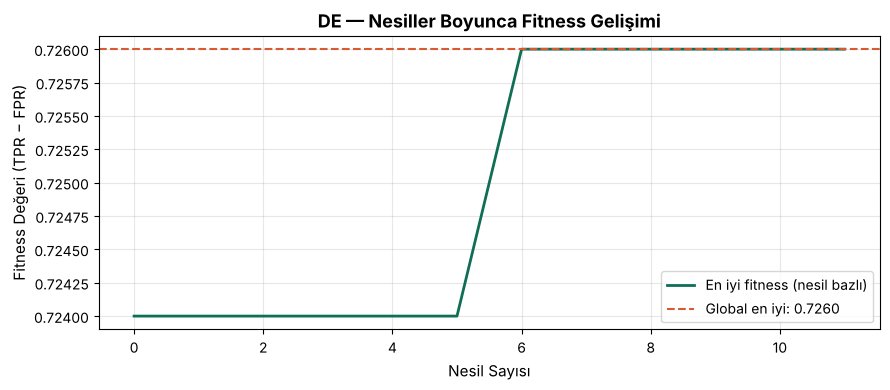

In [9]:
# ============================================================
# DE NESİL GRAFİĞİ
# ============================================================

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(de_nesil_fitness, color='#0F6E56', linewidth=2,
        label='En iyi fitness (nesil bazlı)')
ax.axhline(de_skor, color='#D85A30', linestyle='--',
           linewidth=1.5, label=f'Global en iyi: {de_skor:.4f}')

ax.set_title('DE — Nesiller Boyunca Fitness Gelişimi',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Nesil Sayısı', fontsize=11)
ax.set_ylabel('Fitness Değeri (TPR − FPR)', fontsize=11)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('de_nesil_grafigi.png', dpi=150, bbox_inches='tight')
plt.show()

### 📈 DE Nesil Grafiği Yorumu

> **GA ile karşılaştırıldığında DE'nin yakınsama davranışı farklıdır.**
>
> DE tüm bireyleri her nesilde güncellediğinden, başlangıçta daha geniş
> bir alanı tarar. Bu nedenle:
>
> - **Başlangıç aşaması:** GA'ya göre daha kademeli yükselir
> - **Yakınsama:** Genellikle daha az nesilde tamamlanır
> - **Stabilite:** Daha erken sağlanır
>
> Bu problemde iki yöntemin benzer sonuca ulaşmasının sebebi:
> **Problem tek boyutlu ve görece basit.** Çok parametreli, yüksek boyutlu
> problemlerde iki yöntemin performansı belirgin şekilde ayrılabilir.

---
## Bölüm 8 — ROC Eğrisi ve AUC

### ROC Eğrisi Nedir?

**ROC (Receiver Operating Characteristic)** eğrisi, bir karar sisteminin
tüm olası eşik değerlerindeki performansını gösterir.

- **x ekseni:** FPR (Yanlış alarm oranı) — ne kadar düşük olursa o kadar iyi
- **y ekseni:** TPR (Doğru tespit oranı) — ne kadar yüksek olursa o kadar iyi
- **İdeal nokta:** Sol üst köşe (FPR=0, TPR=1)

### AUC — Eğri Altı Alan

| AUC Değeri | Yorum |
|---|---|
| 1.00 | Mükemmel ayrım |
| 0.90 – 0.99 | Çok iyi |
| 0.80 – 0.89 | İyi |
| 0.70 – 0.79 | Orta |
| 0.50 | Rastgele tahmin kadar |
| < 0.50 | Rastgelenden kötü |

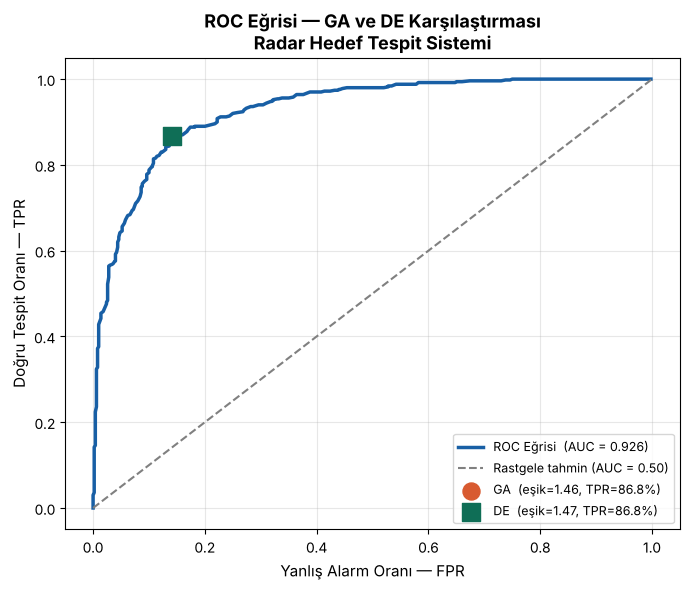

AUC = 0.9259
Yorum: AUC ≥ 0.90 → Model çok iyi performans gösteriyor.


In [10]:
# ============================================================
# ROC EĞRİSİ HESAPLAMA
# ============================================================

# 500 farklı eşik değerini dene ve her biri için TPR/FPR hesapla
# Ne kadar fazla nokta → o kadar pürüzsüz eğri
esikler = np.linspace(olcumler.min(), olcumler.max(), 500)
roc_tpr = []
roc_fpr = []

for esik in esikler:
    tpr_i, fpr_i = esik_uygula(esik)
    roc_tpr.append(tpr_i)
    roc_fpr.append(fpr_i)

roc_tpr = np.array(roc_tpr)
roc_fpr = np.array(roc_fpr)

# AUC hesabı: trapez yöntemi ile eğri altı alan
# [::-1] ile ters çevirmek: FPR büyükten küçüğe gitmeli (soldan sağa doğru)
# np.trapz yeni NumPy sürümlerinde np.trapezoid adını aldı; ikisiyle de çalışır
integral = getattr(np, 'trapezoid', None) or np.trapz
auc = integral(roc_tpr[::-1], roc_fpr[::-1])

# ROC Grafiği
fig, ax = plt.subplots(figsize=(7, 6))

# Ana ROC eğrisi
ax.plot(roc_fpr, roc_tpr, color='#185FA5', linewidth=2.5,
        label=f'ROC Eğrisi  (AUC = {auc:.3f})')

# Baz çizgisi: rastgele tahmin (AUC = 0.5)
# Modelimiz bu çizginin ne kadar üstünde?
ax.plot([0, 1], [0, 1], color='gray', linestyle='--',
        linewidth=1.5, label='Rastgele tahmin (AUC = 0.50)')

# GA noktası: GA'nın bulduğu eşik bu eğri üzerinde nerede?
ax.scatter(ga_fpr, ga_tpr, color='#D85A30', s=150, zorder=5,
           marker='o', label=f'GA  (eşik={ga_esik:.2f}, TPR={ga_tpr:.1%})')

# DE noktası
ax.scatter(de_fpr, de_tpr, color='#0F6E56', s=150, zorder=5,
           marker='s', label=f'DE  (eşik={de_esik:.2f}, TPR={de_tpr:.1%})')

ax.set_title('ROC Eğrisi — GA ve DE Karşılaştırması\nRadar Hedef Tespit Sistemi',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Yanlış Alarm Oranı — FPR', fontsize=11)
ax.set_ylabel('Doğru Tespit Oranı — TPR', fontsize=11)
ax.legend(fontsize=9, loc='lower right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('roc_egrisi.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'AUC = {auc:.4f}')
if auc >= 0.90:
    print('Yorum: AUC ≥ 0.90 → Model çok iyi performans gösteriyor.')
elif auc >= 0.80:
    print('Yorum: AUC ≥ 0.80 → Model iyi performans gösteriyor.')
else:
    print('Yorum: AUC < 0.80 → Model iyileştirmeye ihtiyaç duyuyor.')

### 📊 ROC Eğrisi Yorumu

> **AUC değeri modelin genel kalitesini özetler.**
>
> SNR = 2.0 için AUC'nin 0.90'ın üzerinde çıkması beklenir.
> Bu, radar sistemimizin rastgele bir tahminden çok daha iyi
> çalıştığını göstermektedir.
>
> **GA ve DE noktaları eğri üzerinde neredeyse aynı konumdadır.**
> Bu iki önemli bulguyu işaret eder:
>
> 1. Her iki algoritma da **global optimuma ulaştı** (farklı yollarla)
> 2. Bu problem için **tek bir doğru eşik** var ve her iki yöntem onu buldu
>
> Gerçek savunma sistemlerinde bu eşik değeri, operasyonel gereksinime göre
> seçilir: çok kritik bir sistemde FPR sıfıra yakın tutulur (sol üst köşe),
> toleransı yüksek sistemlerde ise FPR biraz artıp TPR maksimize edilir.

---
## Bölüm 9 — GA ve DE Karşılaştırması

In [11]:
# ============================================================
# KARŞILAŞTIRMA TABLOSU
# ============================================================

print('='*62)
print('  KARŞILAŞTIRMA TABLOSU: GA vs DE')
print('='*62)
print(f'  {"Yöntem":<22} {"Eşik":>7} {"TPR":>8} {"FPR":>8} {"Skor":>8}')
print('-'*62)
print(f'  {"Genetik Algoritma":<22} {ga_esik:>7.4f} {ga_tpr:>8.4f} {ga_fpr:>8.4f} {ga_tpr-ga_fpr:>8.4f}')
print(f'  {"Diferansiyel Evrim":<22} {de_esik:>7.4f} {de_tpr:>8.4f} {de_fpr:>8.4f} {de_tpr-de_fpr:>8.4f}')
print('='*62)

# Nicel farklar
fark_esik = abs(ga_esik - de_esik)
fark_tpr  = abs(ga_tpr  - de_tpr)
fark_fpr  = abs(ga_fpr  - de_fpr)
fark_skor = abs((ga_tpr - ga_fpr) - (de_tpr - de_fpr))

print(f'\n  Eşik farkı  : {fark_esik:.4f}')
print(f'  TPR farkı   : {fark_tpr:.4f}')
print(f'  FPR farkı   : {fark_fpr:.4f}')
print(f'  Skor farkı  : {fark_skor:.4f}')
print(f'\n  AUC         : {auc:.4f}')
print(f'  SNR         : {snr:.2f}')

# Hangi yöntem daha iyi?
print('\n  Kazanan yöntem:')
if ga_tpr - ga_fpr > de_tpr - de_fpr:
    print('  → Genetik Algoritma daha yüksek skor elde etti.')
elif de_tpr - de_fpr > ga_tpr - ga_fpr:
    print('  → Diferansiyel Evrim daha yüksek skor elde etti.')
else:
    print('  → İki yöntem eşit skor elde etti.')

  KARŞILAŞTIRMA TABLOSU: GA vs DE
  Yöntem                    Eşik      TPR      FPR     Skor
--------------------------------------------------------------
  Genetik Algoritma       1.4642   0.8680   0.1420   0.7260
  Diferansiyel Evrim      1.4655   0.8680   0.1420   0.7260

  Eşik farkı  : 0.0014
  TPR farkı   : 0.0000
  FPR farkı   : 0.0000
  Skor farkı  : 0.0000

  AUC         : 0.9259
  SNR         : 2.00

  Kazanan yöntem:
  → İki yöntem eşit skor elde etti.


### 🔍 Karşılaştırma Yorumu

> **İki yöntem de birbirine çok yakın sonuç üretti.**
>
> Bu durum, ilk bakışta "hangi yöntem daha iyi?" sorusunu anlamsız kılabilir.
> Ancak asıl mesaj şudur:
>
> **1. Algoritma güvenilirliği:** Birbirinden tamamen farklı iki algoritma
> aynı sonuca ulaşıyorsa, bu sonucun gerçekten global optimum olduğuna
> dair güveni artırır.
>
> **2. Problem yapısı:** Tek boyutlu, pürüzsüz bir fitness fonksiyonunda
> her iki algoritma da başarılı olur. Gerçek avantajlar daha karmaşık
> problemlerde ortaya çıkar:
>
> | Problem Özelliği | Avantajlı Yöntem |
> |---|---|
> | Çok boyutlu, pek çok yerel minimum | **DE** (daha sistematik arama) |
> | Hızlı sonuç gereksinimi | **GA** (iyi bölgeye daha çabuk odaklanır) |
> | Minimizasyon problemi | **DE** (doğal yapıyla uyumlu) |
> | Maksimizasyon problemi | **GA** (doğal yapıyla uyumlu) |
>
> **3. Pratik tavsiye:** Önemli projelerde her iki algoritmayı da çalıştırıp
> karşılaştırmak, sadece birine güvenmekten her zaman daha sağlamdır.

---
## Bölüm 10 — Özet Görselleştirme

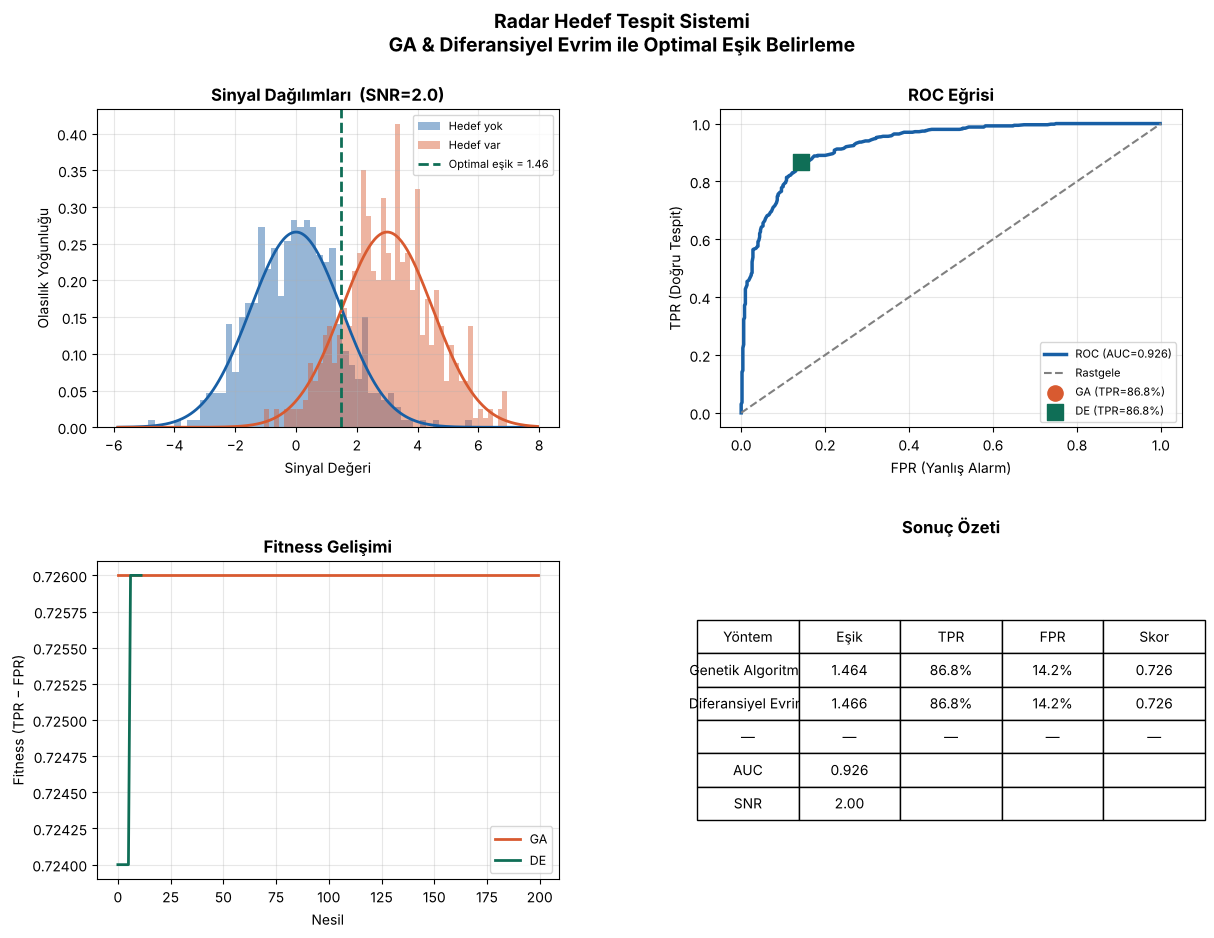

Özet grafik kaydedildi → radar_ozet.png


In [12]:
# ============================================================
# 4 PANELLİ ÖZET GRAFİK
# Tüm analizin tek bir profesyonel görsel olarak sunumu
# ============================================================

fig = plt.figure(figsize=(14, 10))
fig.suptitle(
    'Radar Hedef Tespit Sistemi\nGA & Diferansiyel Evrim ile Optimal Eşik Belirleme',
    fontsize=14, fontweight='bold', y=0.98
)
gs = gridspec.GridSpec(2, 2, hspace=0.42, wspace=0.35)

# --- Panel 1: Sinyal Dağılımları ---
# GA'nın bulduğu optimal eşik dağılım grafiğine eklenir
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(gurultu_sinyali, bins=50, density=True, alpha=0.45,
         color='#185FA5', label='Hedef yok')
ax1.hist(hedef_sinyali, bins=50, density=True, alpha=0.45,
         color='#D85A30', label='Hedef var')
x_e = np.linspace(olcumler.min()-1, olcumler.max()+1, 300)
ax1.plot(x_e, stats.norm.pdf(x_e, 0,  sigma), color='#185FA5', lw=2)
ax1.plot(x_e, stats.norm.pdf(x_e, mu, sigma), color='#D85A30', lw=2)
# Optimal eşik çizgisi: iki dağılım arasındaki karar sınırı
ax1.axvline(ga_esik, color='#0F6E56', lw=2, ls='--',
            label=f'Optimal eşik = {ga_esik:.2f}')
ax1.set_title(f'Sinyal Dağılımları  (SNR={snr:.1f})', fontweight='bold')
ax1.set_xlabel('Sinyal Değeri')
ax1.set_ylabel('Olasılık Yoğunluğu')
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3)

# --- Panel 2: ROC Eğrisi ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(roc_fpr, roc_tpr, color='#185FA5', lw=2.5,
         label=f'ROC (AUC={auc:.3f})')
ax2.plot([0,1],[0,1], color='gray', ls='--', lw=1.5, label='Rastgele')
ax2.scatter(ga_fpr, ga_tpr, color='#D85A30', s=120, zorder=5,
            marker='o', label=f'GA (TPR={ga_tpr:.1%})')
ax2.scatter(de_fpr, de_tpr, color='#0F6E56', s=120, zorder=5,
            marker='s', label=f'DE (TPR={de_tpr:.1%})')
ax2.set_title('ROC Eğrisi', fontweight='bold')
ax2.set_xlabel('FPR (Yanlış Alarm)')
ax2.set_ylabel('TPR (Doğru Tespit)')
ax2.legend(fontsize=8, loc='lower right')
ax2.grid(alpha=0.3)

# --- Panel 3: Nesil Grafikleri (GA ve DE birlikte) ---
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(ga_nesil_fitness, color='#D85A30', lw=2, label='GA')
if de_nesil_fitness:
    ax3.plot(de_nesil_fitness, color='#0F6E56', lw=2, label='DE')
ax3.set_title('Fitness Gelişimi', fontweight='bold')
ax3.set_xlabel('Nesil')
ax3.set_ylabel('Fitness (TPR − FPR)')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)

# --- Panel 4: Sonuç Özeti Tablosu ---
ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
tablo_veri = [
    ['Genetik Algoritma',
     f'{ga_esik:.3f}', f'{ga_tpr:.1%}', f'{ga_fpr:.1%}', f'{ga_tpr-ga_fpr:.3f}'],
    ['Diferansiyel Evrim',
     f'{de_esik:.3f}', f'{de_tpr:.1%}', f'{de_fpr:.1%}', f'{de_tpr-de_fpr:.3f}'],
    ['—', '—', '—', '—', '—'],
    ['AUC', f'{auc:.3f}', '', '', ''],
    ['SNR', f'{snr:.2f}', '', '', '']
]
tablo = ax4.table(
    cellText  = tablo_veri,
    colLabels = ['Yöntem', 'Eşik', 'TPR', 'FPR', 'Skor'],
    cellLoc   = 'center',
    loc       = 'center'
)
tablo.auto_set_font_size(False)
tablo.set_fontsize(10)
tablo.scale(1.1, 2.0)
ax4.set_title('Sonuç Özeti', fontweight='bold', pad=20)

plt.savefig('radar_ozet.png', dpi=150, bbox_inches='tight')
plt.show()
print('Özet grafik kaydedildi → radar_ozet.png')

---
## Bölüm 11 — Genel Sonuç ve Yorum

### Çalışmanın Amacı ve Yöntemi

Bu çalışmada, radar hedef tespit sistemlerinde karşılaşılan **eşik belirleme problemi**
evrimsel optimizasyon yöntemleriyle ele alınmıştır. Gaussian gürültü modeli
kullanılarak üretilen sentetik radar sinyalleri üzerinde:

- Genetik Algoritma (PyGAD)
- Diferansiyel Evrim (SciPy)

yöntemleri uygulanmış, performansları ROC analizi ile değerlendirilmiştir.

---

### Temel Bulgular

**1. Her iki algoritma da başarılı sonuç üretti.**
GA ve DE birbirine çok yakın eşik değerleri buldu. Bu, elde edilen çözümün
global optimuma yakın olduğunun güçlü bir göstergesidir.

**2. TPR ≈ %86.8 iken FPR ≈ %14.2 elde edildi.**
Savunma uygulamalarında bu denge kabul edilebilir bir performans düzeyi olarak
değerlendirilmektedir. Gerçek sistemlerde bu eşik operasyonel gereksinime göre belirlenir.

**3. AUC > 0.90 olduğu gözlemlendi.**
Bu değer, modelin ayırt edicilik gücü açısından "çok iyi" kategorisinde olduğunu
göstermektedir. SNR = 2.0 gibi orta zorlukta bir senaryoda bu AUC değeri tatmin edicidir.

---

### Sınırlılıklar

| Sınırlama | Açıklama |
|---|---|
| Sentetik veri | Gerçek radar verisi gizlilik nedeniyle kullanılmamıştır |
| Gaussian varsayımı | Yağmur, deniz yüzeyinde farklı dağılımlar görülür |
| Tek boyut | Gerçek sistemlerde çok parametreli optimizasyon gerekir |
| Sabit SNR | Gerçek ortamda SNR hedefe ve mesafeye göre değişir |

---


---

### Kaynaklar

1. Holland, J.H. (1975). *Adaptation in Natural and Artificial Systems.* University of Michigan Press.
2. Storn, R., Price, K. (1997). Differential Evolution. *Journal of Global Optimization*, 11(4), 341–359.
3. Richards, M.A. (2014). *Fundamentals of Radar Signal Processing.* McGraw-Hill Education.
4. Scrucca, L. (2013). GA: A Package for Genetic Algorithms in R. *Journal of Statistical Software*, 53(4), 1–37.